# Figure 14.1 — Thermionic emission, tunneling, and space-charge current

Thermionic transport samples the high-energy tail, tunneling samples the evanescent wave, and strong injection couples current to Poisson electrostatics.

## Direct NumPy calculation

The governing relations are evaluated explicitly before the reusable course implementation is imported.

300 K thermal voltage = 0.025852 V
T(E=0.4 eV, d=1 nm) = 1.3633e-01


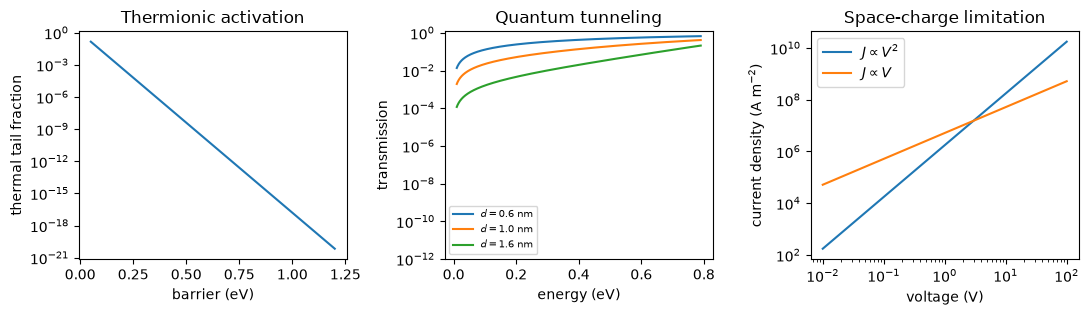

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

q = 1.602_176_634e-19
k_B = 1.380_649e-23
hbar = 1.054_571_817e-34
m_0 = 9.109_383_7139e-31
eps_0 = 8.854_187_8128e-12
T = 300.0
V_T = k_B*T/q

barrier_ev = np.linspace(0.05, 1.2, 500)
thermal_tail = np.exp(-barrier_ev/V_T)
energy_ev = np.linspace(0.01, 0.79, 600)
barrier_j = 0.8*q
mass = 0.26*m_0

def transmission(width_nm):
    E = energy_ev*q
    kappa = np.sqrt(2*mass*(barrier_j-E))/hbar
    return 1/(1 + barrier_j**2*np.sinh(np.minimum(kappa*width_nm*1e-9, 350))**2/(4*E*(barrier_j-E)))

assert np.all(transmission(1.2) < transmission(0.6))
voltage = np.logspace(-2, 2, 500)
eps = 11.7*eps_0
mu, length, v_sat = 0.12, 2e-6, 1e5
J_mu = 9*eps*mu*voltage**2/(8*length**3)
J_sat = 2*eps*v_sat*voltage/length**2
assert np.isclose(J_mu[-1]/J_mu[-2], (voltage[-1]/voltage[-2])**2)

fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
axes[0].semilogy(barrier_ev, thermal_tail)
axes[0].set(xlabel="barrier (eV)", ylabel="thermal tail fraction", title="Thermionic activation")
for width in (0.6, 1.0, 1.6):
    axes[1].semilogy(energy_ev, transmission(width), label=fr"$d={width}$ nm")
axes[1].set(xlabel="energy (eV)", ylabel="transmission", title="Quantum tunneling", ylim=(1e-12, 1.2))
axes[1].legend(fontsize=7)
axes[2].loglog(voltage, J_mu, label=r"$J\propto V^2$")
axes[2].loglog(voltage, J_sat, label=r"$J\propto V$")
axes[2].set(xlabel="voltage (V)", ylabel=r"current density (A m$^{-2}$)", title="Space-charge limitation")
axes[2].legend()
print(f"300 K thermal voltage = {V_T:.6f} V")
print(f"T(E=0.4 eV, d=1 nm) = {transmission(1.0)[np.argmin(abs(energy_ev-0.4))]:.4e}")
fig.tight_layout()
plt.show()

## Finite-difference barrier and space-charge calculations

The numerical extension discretizes three boundary-value problems:

1. the open-boundary Schrödinger equation for tunneling;
2. Poisson's equation for an arbitrary prescribed charge density; and
3. the self-consistent space-charge field with current and voltage constraints.

In [2]:
# Cell-centered finite-difference Hamiltonian with open discrete leads.
energy_fd_ev = np.linspace(0.03, 0.79, 120)
energy_fd = energy_fd_ev*q
width_fd, points_fd = 1.0e-9, 100
dx_fd = width_fd/points_fd
hopping = hbar**2/(2*mass*dx_fd**2)
transmission_fd = np.empty_like(energy_fd)

for index, E in enumerate(energy_fd):
    # E = 2*t0*(1-cos(k*dx)) is the dispersion of a zero-potential FD lead.
    kdx = np.arccos(1-E/(2*hopping))
    self_energy = -hopping*np.exp(1j*kdx)
    broadening = -2*np.imag(self_energy)
    system = lil_matrix((points_fd, points_fd), dtype=complex)
    system.setdiag(np.full(points_fd, E-(2*hopping+barrier_j)))
    system.setdiag(np.full(points_fd-1, hopping), k=1)
    system.setdiag(np.full(points_fd-1, hopping), k=-1)
    system[0, 0] -= self_energy
    system[-1, -1] -= self_energy
    source = np.zeros(points_fd, dtype=complex)
    source[-1] = 1
    green_1N = spsolve(system.tocsr(), source)[0]
    transmission_fd[index] = broadening**2*abs(green_1N)**2

# Exact rectangular-barrier result on the same energy points.
kappa_fd = np.sqrt(2*mass*(barrier_j-energy_fd))/hbar
transmission_exact = 1/(1 + barrier_j**2*np.sinh(kappa_fd*width_fd)**2/(4*energy_fd*(barrier_j-energy_fd)))
transmission_l2 = np.linalg.norm(transmission_fd-transmission_exact)/np.linalg.norm(transmission_exact)
assert transmission_l2 < 1e-4
print(f"finite-difference transmission relative L2 error = {transmission_l2:.3e}")

finite-difference transmission relative L2 error = 5.882e-05


In [3]:
# Centered finite-difference Poisson solve for a uniform test charge.
x_poisson = np.linspace(0.0, 2.0e-6, 101)
dx_poisson = x_poisson[1]-x_poisson[0]
rho_test = 3.0e3  # C/m^3
interior = x_poisson.size-2
poisson_matrix = lil_matrix((interior, interior))
poisson_matrix.setdiag(np.full(interior, -2.0))
poisson_matrix.setdiag(np.ones(interior-1), k=1)
poisson_matrix.setdiag(np.ones(interior-1), k=-1)
poisson_rhs = np.full(interior, -dx_poisson**2*rho_test/eps)
phi_fd = np.zeros_like(x_poisson)
phi_fd[1:-1] = spsolve(poisson_matrix.tocsr(), poisson_rhs)
phi_exact = rho_test*x_poisson*(x_poisson[-1]-x_poisson)/(2*eps)
poisson_relative_error = np.max(abs(phi_fd-phi_exact))/np.max(phi_exact)
assert poisson_relative_error < 1e-10
print(f"Poisson maximum relative error = {poisson_relative_error:.3e}")

Poisson maximum relative error = 7.606e-15


In [4]:
def solve_sclc_fd(applied_voltage, mode, grid_points=81):
    """Solve dE/dx=J/(epsilon*v) with E(0)=0 and integral(E dx)=V."""
    x = np.linspace(0.0, length, grid_points)
    dx = x[1]-x[0]
    field_scale = applied_voltage/length
    if mode == "mobility":
        current_guess = 9*eps*mu*applied_voltage**2/(8*length**3)
        field_guess = np.sqrt(2*current_guess*x/(eps*mu))
    elif mode == "saturation":
        current_guess = 2*eps*v_sat*applied_voltage/length**2
        field_guess = 2*applied_voltage*x/length**2
    else:
        raise ValueError(mode)

    initial = np.r_[field_guess/field_scale, current_guess]
    def residual(unknown):
        field = unknown[:-1]*field_scale
        current = unknown[-1]
        midpoint = 0.5*(field[:-1]+field[1:])
        speed = mu*midpoint if mode == "mobility" else np.full_like(midpoint, v_sat)
        value = np.empty(grid_points+1)
        value[0] = field[0]/field_scale
        value[1:-1] = (field[1:]-field[:-1]-dx*current/(eps*speed))/field_scale
        value[-1] = (np.trapezoid(field, x)-applied_voltage)/applied_voltage
        return value

    result = least_squares(residual, initial, bounds=(0, np.inf), xtol=1e-12, ftol=1e-12, gtol=1e-12)
    assert result.success and np.max(abs(residual(result.x))) < 1e-7
    return x, result.x[:-1]*field_scale, result.x[-1]

x_mu, field_mu, current_mu = solve_sclc_fd(2.0, "mobility")
x_sat, field_sat, current_sat = solve_sclc_fd(2.0, "saturation")
expected_mu = 9*eps*mu*2.0**2/(8*length**3)
expected_sat = 2*eps*v_sat*2.0/length**2
assert np.isclose(current_mu, expected_mu, rtol=1e-3)
assert np.isclose(current_sat, expected_sat, rtol=1e-8)
print(f"Mott-Gurney current relative error = {current_mu/expected_mu-1:.3e}")
print(f"constant-velocity current relative error = {current_sat/expected_sat-1:.3e}")

Mott-Gurney current relative error = 8.526e-04
constant-velocity current relative error = -6.667e-11


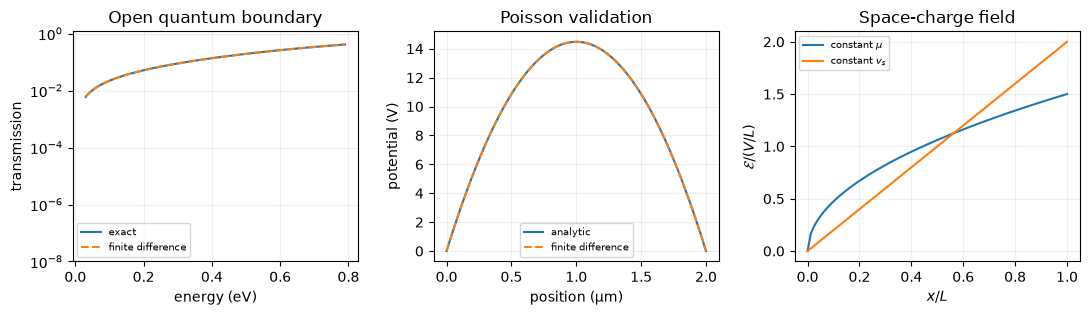

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
axes[0].semilogy(energy_fd_ev, transmission_exact, label="exact")
axes[0].semilogy(energy_fd_ev, transmission_fd, "--", label="finite difference")
axes[0].set(xlabel="energy (eV)", ylabel="transmission", title="Open quantum boundary", ylim=(1e-8, 1.2))
axes[0].legend(fontsize=7)

axes[1].plot(x_poisson*1e6, phi_exact, label="analytic")
axes[1].plot(x_poisson*1e6, phi_fd, "--", label="finite difference")
axes[1].set(xlabel="position (µm)", ylabel="potential (V)", title="Poisson validation")
axes[1].legend(fontsize=7)

axes[2].plot(x_mu/length, field_mu/(2.0/length), label=r"constant $\mu$")
axes[2].plot(x_sat/length, field_sat/(2.0/length), label=r"constant $v_s$")
axes[2].set(xlabel=r"$x/L$", ylabel=r"$\mathcal{E}/(V/L)$", title="Space-charge field")
axes[2].legend(fontsize=7)
for axis in axes: axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Reusable publication implementation

The tested course implementation writes the deterministic PDF used by the manuscript.

In [6]:
import sys
from pathlib import Path

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "main.tex").exists()
)
sys.path.insert(0, str(ROOT / "figures" / "src"))

from semphy.transport_extensions import (
    barrier_space_charge_figure,
    barrier_space_charge_numerics_figure,
)

barrier_space_charge_figure()
barrier_space_charge_numerics_figure()
print("wrote transport-barriers-space-charge.pdf")
print("wrote transport-barrier-sclc-numerics.pdf")

wrote transport-barriers-space-charge.pdf
wrote transport-barrier-sclc-numerics.pdf
